# Why does Ramen send DomainNet images to *pillow*, and does a true-label cache stop it?

**Question.** After Ramen's adaptation, DomainNet images are predicted *pillow* far more often than before.
For those images: what was the class before adaptation, what is it after, and what was in Ramen's cache when
each image arrived? And what changes if the cache is filled using the true labels instead (an oracle)?

**What was already known** (`2026-10-28_confusion_records`, notebook 04): Ramen's wrong *pillow* predictions
grow from 1,147 (zero-shot) to 6,484. They are mostly quickdraw images that zero-shot called *envelope* or
*squiggle*. The sink is moved to another wrong class, not repaired.

**Hypotheses** (written before the cache replay was run):
- **H1, contamination.** Ramen files each image under its *zero-shot* prediction, so the *envelope*, *squiggle*
  and *pillow* queues are full of quickdraw rectangles of other classes. If those mis-filed entries cause the
  sink, the oracle cache (every queue pure) should keep fewer than 20% of Ramen's wrong *pillow* predictions
  at *pillow*.
- **H2, neighbours.** If instead the update is set by *who the image's neighbours are*, whatever queue they are
  filed in, the oracle cache retrieves largely the same entries (high "weight on entries both caches
  retrieve"). The sink then survives.

**Why this test.** Ramen's cache never depends on its adapted outputs. Each image is written, before retrieval,
with its zero-shot feature, its zero-shot entropy and its own gradient, so both caches can be **replayed
offline** (no GPU) from the recorded features, and replayed exactly. Only the oracle's adapted predictions need
a GPU run.

**What is compared.**

| Source | What it is | Uses true labels? |
|---|---|---|
| zero-shot | CLIP before adaptation (the pass that files each image in the cache) | no |
| Ramen | Ramen as published: each image is filed in the queue of its **zero-shot** prediction | no |
| oracle cache | `RamenTrueLabel`, `filing: true_label`: each image is filed in the queue of its **true** label; everything else is Ramen's | **yes: an upper bound, not a method** |

**Data.** DomainNet, 6 domains, 345 classes, 596,006 images, CLIP ViT-B/32, one mixed (shuffled) stream, batch
size 100. Config `cfg/DomainNet/Ramen.yaml`: queue capacity 300, top-k 10, β 5, signSGD lr 0.01. The oracle
uses the same values. Both runs use the default fp16 priorities, so full queues stop changing after 65,520
images.

**Seeds.** Seed 0 only. A seed sets the order of the stream. The *pillow* counts for seeds 1–4 come from the
cached plain Ramen runs (section 4.4). This is a descriptive case study, not an accuracy claim, so the noise floor
(0.11 pts on DomainNet) is not the test. The counts are.

**How the results were produced.**
```
cd new_experiments/2026-10-28_confusion_records
CUDA_VISIBLE_DEVICES=0 python run_records.py DomainNet 0                                     # Ramen, recorded (2026-10-28)
CUDA_VISIBLE_DEVICES=0 python run_records.py DomainNet 0 --variant true_label --skip-check   # oracle, recorded (2026-11-01, 36 min)
```
`--skip-check` skips the built-in check against an uncached plain `true_label` run. Cell 3.1 checks the recording
against the cached `oracle_file_true` run (same oracle, earlier code path) instead. Code in this folder:
`sink_runs.py`, `sink_trace.py`, `cache_replay.py`, `example_card.py`, `sink_plots.py`, `case_study.py`. The
cache replay is stored as `results/DomainNet_..._s0_pillow_sink_replay_pillow.pkl`.

**How to read this notebook.**
1. Setup
2. The data
3. Sanity checks
4. Where *pillow* predictions come from
5. What the two caches retrieve, over all images
6. Examples, image by image
7. Interpretation
8. Glossary

Counts are given with percentages. Accuracies are domain-averaged unless stated.

## 1. Setup

In [1]:
import os, sys
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')  # no GPU needed: the text features and the replay are cached
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import ramen_analysis  # palette; puts src/ on the path

from case_study import SinkCaseStudy
from sink_plots import plot_prediction_counts, plot_routes, plot_update_sources, plot_queue_history

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
DATASET, SEED, TARGET = 'DomainNet', 0, 'pillow'
study = SinkCaseStudy(DATASET, seed=SEED, target=TARGET)
runs, trace, card = study.runs, study.trace, study.card

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. The data
Images and classes per domain. These are the denominators for everything below.

In [2]:
runs.data_table()

,images,classes present
domain,,
clipart,48833,345
infograph,53201,345
painting,75759,345
quickdraw,172500,345
real,175327,345
sketch,70386,345
all,596006,345


Accuracy of the three sources per domain (correct images and %). The last row is the domain average, the headline convention.

In [3]:
runs.accuracy_table()

,images,zero-shot correct,zero-shot %,Ramen correct,Ramen %,oracle cache correct,oracle cache %
domain,,,,,,,
clipart,48833,33326,68.24,33856,69.33,33502,68.61
infograph,53201,23348,43.89,23931,44.98,23685,44.52
painting,75759,48926,64.58,49771,65.70,49667,65.56
quickdraw,172500,22991,13.33,30256,17.54,19058,11.05
real,175327,143983,82.12,144244,82.27,144125,82.20
sketch,70386,42266,60.05,42908,60.96,42112,59.83
domain avg,596006,314840,55.37,324966,56.80,312149,55.29


## 3. Sanity checks
### 3.1 The recorded runs
Each recording must predict exactly what its plain cached run predicts (100.00%). Both recordings must see the same stream, starting from the same zero-shot embeddings. The logits used below are recomputed as 100 · embedding · text featureᵀ: their argmax must give the recorded zero-shot class, up to fp16 near-ties.

In [4]:
runs.sanity_check()

,result
check,
recorded Ramen prediction == cached Ramen,"596,006 of 596,006 (100.0%)"
recorded true_label prediction == cached oracle_file_true,"596,006 of 596,006 (100.0%)"
Ramen and oracle runs see the same stream,yes
"zero-shot embedding, Ramen vs oracle run (max |diff|, 20,000 images)",0.00e+00
argmax of recomputed zero-shot logits == recorded zero-shot class,"19,953 of 20,000 (99.8%)"
softmax(recomputed logits) vs recorded zero-shot probs: median / max |diff|,5.3e-04 / 6.4e-03


### 3.2 The cache replay
The zero-shot-filed replay is compared with what a `RamenActive` *all* run (identical to Ramen on this stream) logged for 200 random images: the contents of the predicted class's queue, and the 8 highest-weight retrieved entries. The oracle replay runs the same code with a different filing rule, so it has no log of its own to check against.

In [5]:
study.validate_replay()

queries checked                             200.00
queue of the predicted class identical %    100.00
top-1 retrieved entry identical %            98.50
top-8 retrieved entries overlap %            98.69
dtype: float64

## 4. Where *pillow* predictions come from
### 4.1 How often each model predicts *pillow*

,predicts pillow,correct,wrong,recall of true pillow %
zero-shot,2101,954,1147,54.95
Ramen,7605,1121,6484,64.57
oracle cache,4710,1031,3679,59.39


truly pillow: 1,736 images


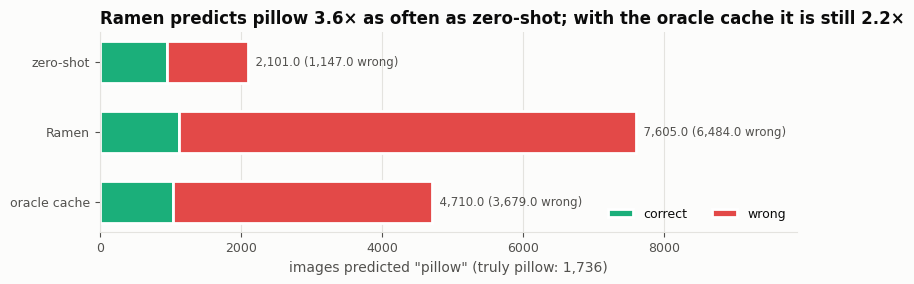

In [6]:
c = trace.counts(); display(c); print(f"truly {TARGET}: {c.attrs['true images']:,} images")
plot_prediction_counts(trace); plt.show()

### 4.2 Routes into *pillow*: the zero-shot class of Ramen's wrong *pillow* predictions
Each route is split by what the oracle cache predicts for the same image: still *pillow*, correct, or another wrong class.

oracle,images,% of wrong,still target,correct,other wrong
envelope → pillow,3570,55.1,969,26,2575
squiggle → pillow,1248,19.2,111,0,1137
pillow → pillow,822,12.7,767,4,51
other,844,13.0,319,12,513
all,6484,100.0,2166,42,4276


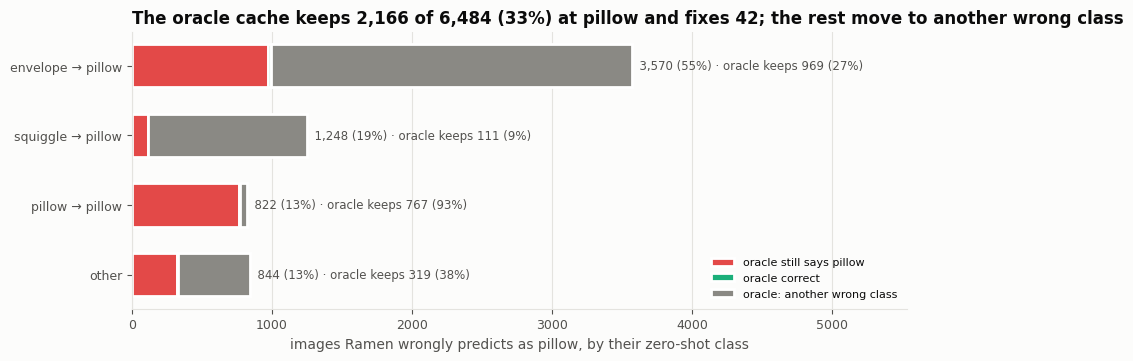

still target    2,166 of 6,484 (33.4%)
correct             42 of 6,484 (0.6%)
other wrong     4,276 of 6,484 (65.9%)


In [7]:
display(trace.routes())
plot_routes(trace); plt.show()
print(trace.oracle_fate().to_string())

What those images truly are, where they are, and where the oracle sends the ones it moves away from *pillow*:

In [8]:
display(trace.true_classes())
display(trace.by_domain())
display(trace.oracle_moves_to())

,images,% of wrong
square,259,4.0
laptop,199,3.1
picture_frame,181,2.8
door,180,2.8
map,178,2.7
The_Mona_Lisa,159,2.5
keyboard,153,2.4
postcard,150,2.3
dishwasher,142,2.2
oven,140,2.2


,images,zero-shot wrong pillow,Ramen wrong pillow,oracle wrong pillow
domain,,,,
clipart,48833,36,31,32
infograph,53201,33,40,35
painting,75759,118,96,123
quickdraw,172500,773,6129,3275
real,175327,96,110,110
sketch,70386,91,78,104
all,596006,1147,6484,3679


oracle_class
envelope       2412
squiggle       1543
smiley_face      63
triangle         36
underwear        35
pear             21
circle           18
tooth            16
Name: images, dtype: int64

Where the oracle sends them is mostly **back to their zero-shot class**. On quickdraw the oracle cache keeps the zero-shot prediction much more often than Ramen does. It adapts less there; it does not repair.

In [9]:
display(trace.oracle_returns_to_zero_shot().to_frame(''))
display(trace.same_as_zero_shot())

,
moved away from the target by the oracle,"4,318 of 6,484"
back to their zero-shot class,"3,499 of 4,318 (81.0%)"


,images,Ramen keeps zero-shot %,oracle keeps zero-shot %
domain,,,
clipart,48833,88.4,88.8
infograph,53201,83.7,85.0
painting,75759,89.7,90.4
quickdraw,172500,48.0,66.8
real,175327,95.1,95.4
sketch,70386,86.7,86.8
all,596006,78.2,84.0


### 4.3 Is it the same on other seeds?
Plain Ramen, seeds 0–4. A seed reorders the stream.

In [10]:
trace.seed_table()

,Ramen predicts pillow,correct,wrong
seed 0,7605,1121,6484
seed 1,7543,1127,6416
seed 2,7362,1112,6250
seed 3,7418,1101,6317
seed 4,7249,1107,6142
mean ± std,"7,435 ± 142","1,114 ± 10","6,322 ± 135"


## 5. What the two caches retrieve, over all images
### 5.1 The *pillow* queue over the stream
How much of the *pillow* queue is truly *pillow*, and how much comes from quickdraw, under each cache. After the dashed line the fp16 counter has saturated: new entries replace the older ones once, and the queue freezes at the tick mark.

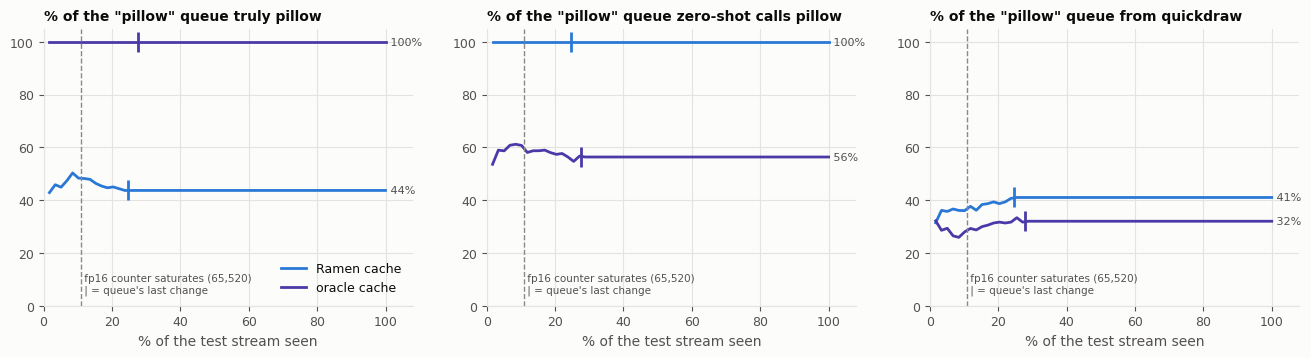

In [11]:
plot_queue_history(study.result.history, TARGET, len(runs.table), domain_name="quickdraw",
                   domain_col=study.domain_col("quickdraw")); plt.show()

### 5.2 Where each image's update comes from
For each test image, Ramen sums the weighted gradients of the retrieved entries: the top 10 of every non-empty queue, weighted by e^(−H)·e^(−5d). The table gives the mean share of that weight, in %, coming from each source, for four groups of images. *Entries zero-shot-predicted pillow* matters because an entry's stored gradient sharpens **its own** zero-shot prediction, whichever queue it is filed in.

images  self  from pillow queue  from zero-shot-class queue  from true-class queue  entries truly pillow  entries zero-shot-predicted pillow  \
Ramen wrong pillow, oracle still pillow Ramen cache     2166   0.1                1.3                         1.0                    0.4                   0.7                                 1.3   
                                        oracle cache    2166   0.2                1.1                         1.5                    0.7                   1.1                                 2.7   
Ramen wrong pillow, oracle not pillow   Ramen cache     4318   0.0                1.0                         0.6                    0.4                   0.5                                 1.0   
                                        oracle cache    4318   0.1                0.6                         1.3                    0.6                   0.6                                 1.1   
zero-shot envelope → Ramen correct      Ramen cache      800   0.0                0.8                         0.6                    0.9                   0.4                                 0.8   
                                        oracle cache     800   0.2                0.6                         1.8                    1.0                   0.6                                 1.0   
true pillow, zero-shot and Ramen right  Ramen cache      918   1.2                4.0                         4.0                    4.0                   4.0                                 4.0   
                                        oracle cache     918   1.5                5.0                         5.0                    5.0                   5.0                                 6.8   

                                                      entries zero-shot-predicted as query's zero-shot class  entries truly query's class  entries that are zero-shot errors  entries from query's domain  \
Ramen wrong pillow, oracle still pillow Ramen cache                                                 1.0                               0.8                               42.0                         62.2   
                                        oracle cache                                               15.4                               0.7                               77.6                         90.1   
Ramen wrong pillow, oracle not pillow   Ramen cache                                                 0.6                               0.6                               46.5                         66.7   
                                        oracle cache                                               30.4                               0.6                               88.9                         99.2   
zero-shot envelope → Ramen correct      Ramen cache                                                 0.6                               1.1                               42.2                         60.5   
                                        oracle cache                                               23.9                               1.0                               80.6                         88.9   
true pillow, zero-shot and Ramen right  Ramen cache                                                 4.0                               4.0                               18.1                         57.3   
                                        oracle cache                                                6.8                               5.0                               30.8                         59.5   

                                                      top-10 entries truly pillow  non-empty queues  weight on entries both caches retrieve  
Ramen wrong pillow, oracle still pillow Ramen cache                           0.8             344.8                                    21.3  
                                        oracle cache                          1.0             344.8                                    23.1  

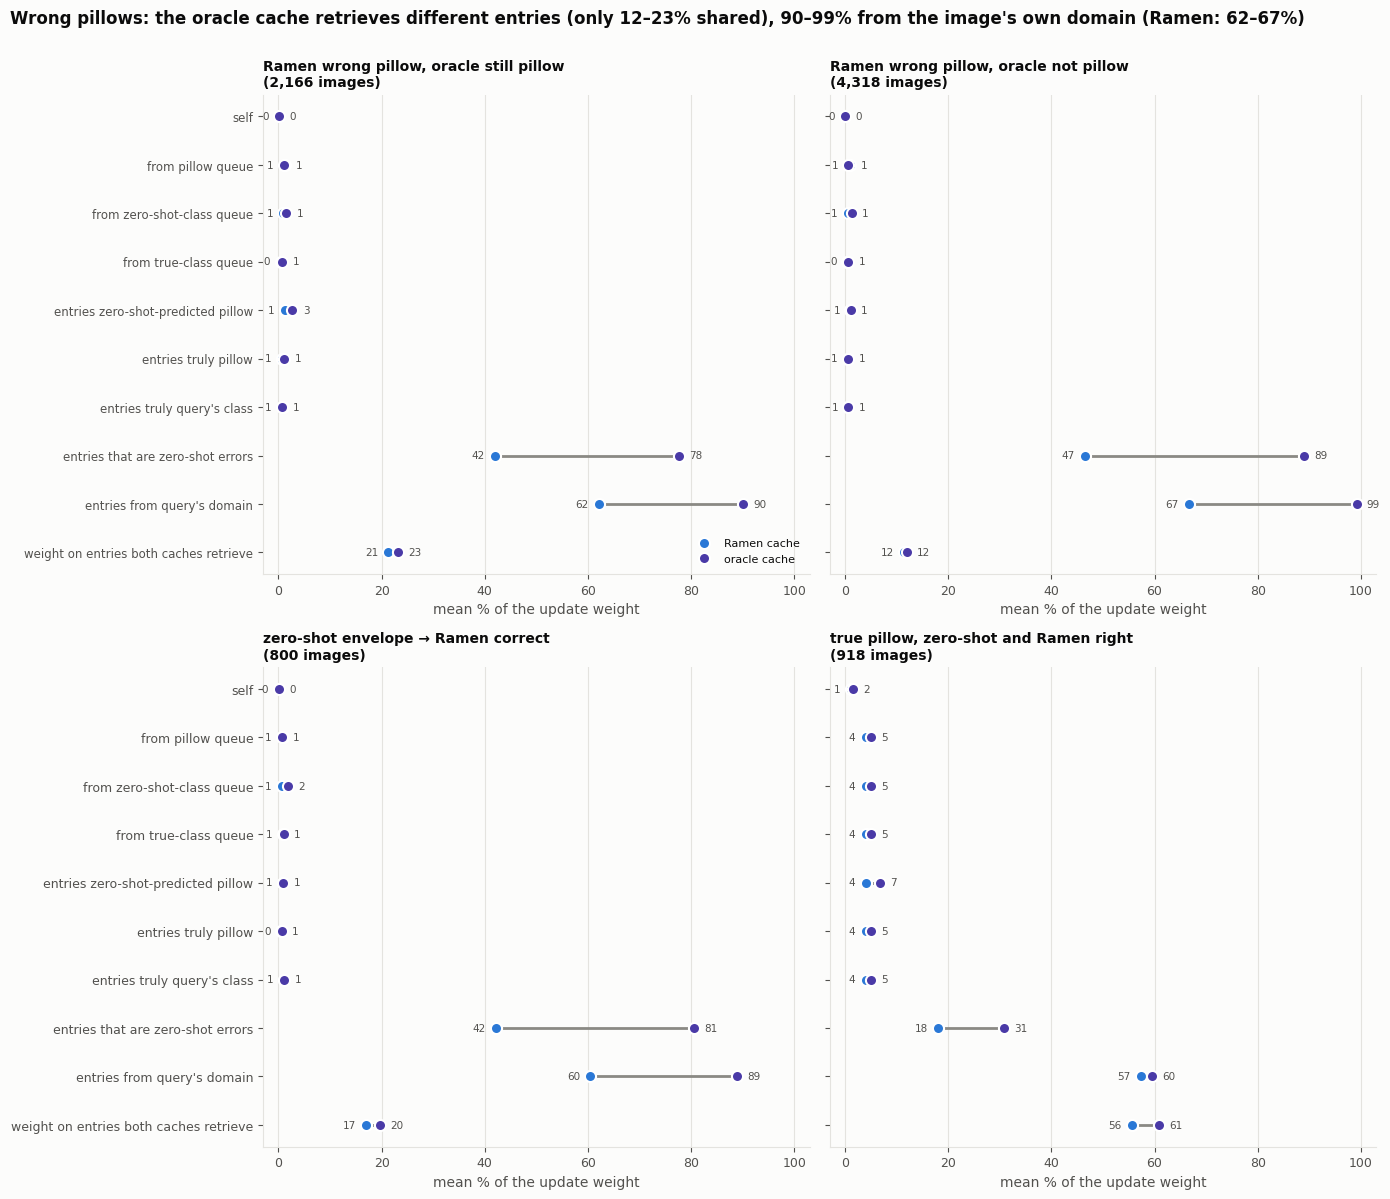

In [12]:
g = study.group_summary(); display(g)
w = g.loc[[k for k in g.index if k[0].startswith("Ramen wrong")]]
ov = w.xs("oracle cache", level=1)["weight on entries both caches retrieve"]
dom = w["entries from query's domain"]
title = (f"Wrong {TARGET}s: the oracle cache retrieves different entries (only {ov.min():.0f}–{ov.max():.0f}% shared), "
         f"{dom.xs('oracle cache', level=1).min():.0f}–{dom.xs('oracle cache', level=1).max():.0f}% from the image's own domain "
         f"(Ramen: {dom.xs('Ramen cache', level=1).min():.0f}–{dom.xs('Ramen cache', level=1).max():.0f}%)")
plot_update_sources(study.result.summary, study.groups, TARGET, title=title); plt.show()

## 6. Examples, image by image
Images drawn at random (fixed seed, not hand-picked) after the first 20% of the stream, so the cache is full. Each example shows:
- the logits and probabilities of the classes that matter, under the three sources (table, then figure);
- for each cache: the share of the update per queue, the 10 highest-weight retrieved entries, and the newest entries of the *pillow* queue at that moment;
- the summary of where the update weight came from.

In [13]:
study.examples

,zero-shot class,Ramen,oracle,true class,domain,stream position %
row,,,,,,
432907,envelope,wrong target,still target,door,quickdraw,72.6
534661,envelope,wrong target,still target,laptop,quickdraw,89.7
336466,envelope,wrong target,other wrong,book,quickdraw,56.5
542621,squiggle,wrong target,still target,chair,quickdraw,91.0
509175,squiggle,wrong target,other wrong,map,quickdraw,85.4
471070,pillow,wrong target,any,squiggle,painting,79.0
447664,envelope,correct,any,book,clipart,75.1
328061,pillow,right target,any,pillow,real,55.0


### Example 1: zero-shot *envelope* → Ramen wrong pillow, oracle cache: still pillow
Image #432,907 of the stream (72.6% in), domain **quickdraw**, true class **door**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
door,true,22.93,20.28,20.08,0.000,0.000,0.000
envelope,zero-shot,28.97,28.74,30.32,0.163,0.031,0.319
pillow,"Ramen, oracle, target",26.88,32.02,30.66,0.020,0.832,0.450
squiggle,,28.40,26.50,27.75,0.091,0.003,0.025
underwear,,25.80,28.09,28.34,0.007,0.016,0.045
toe,,27.49,24.86,25.92,0.037,0.001,0.004
smiley_face,,27.49,26.44,27.03,0.037,0.003,0.012
eraser,,27.46,26.67,27.05,0.036,0.004,0.012


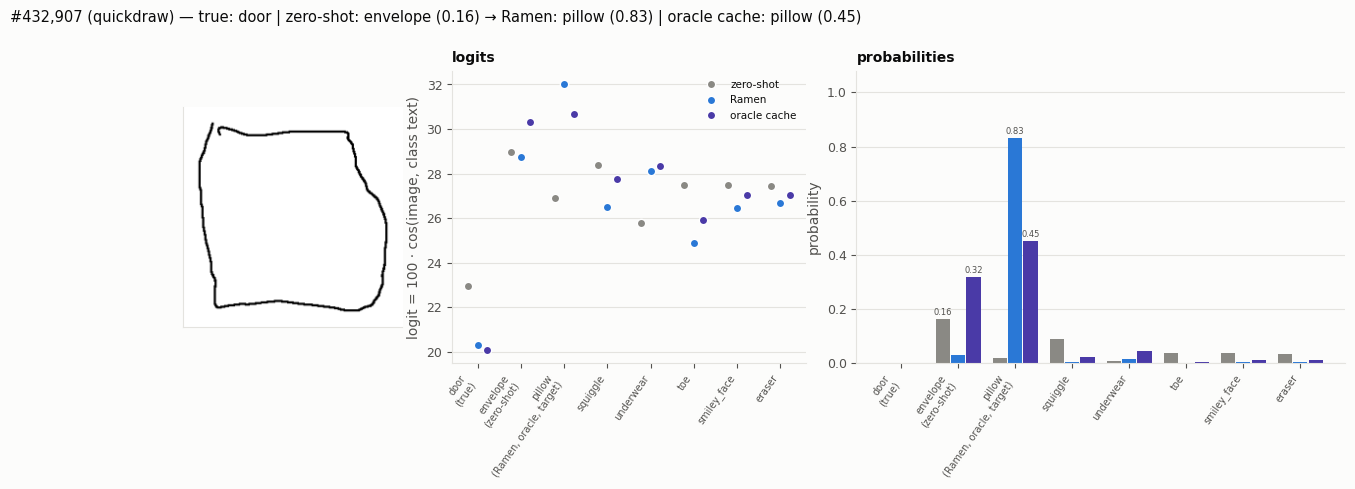

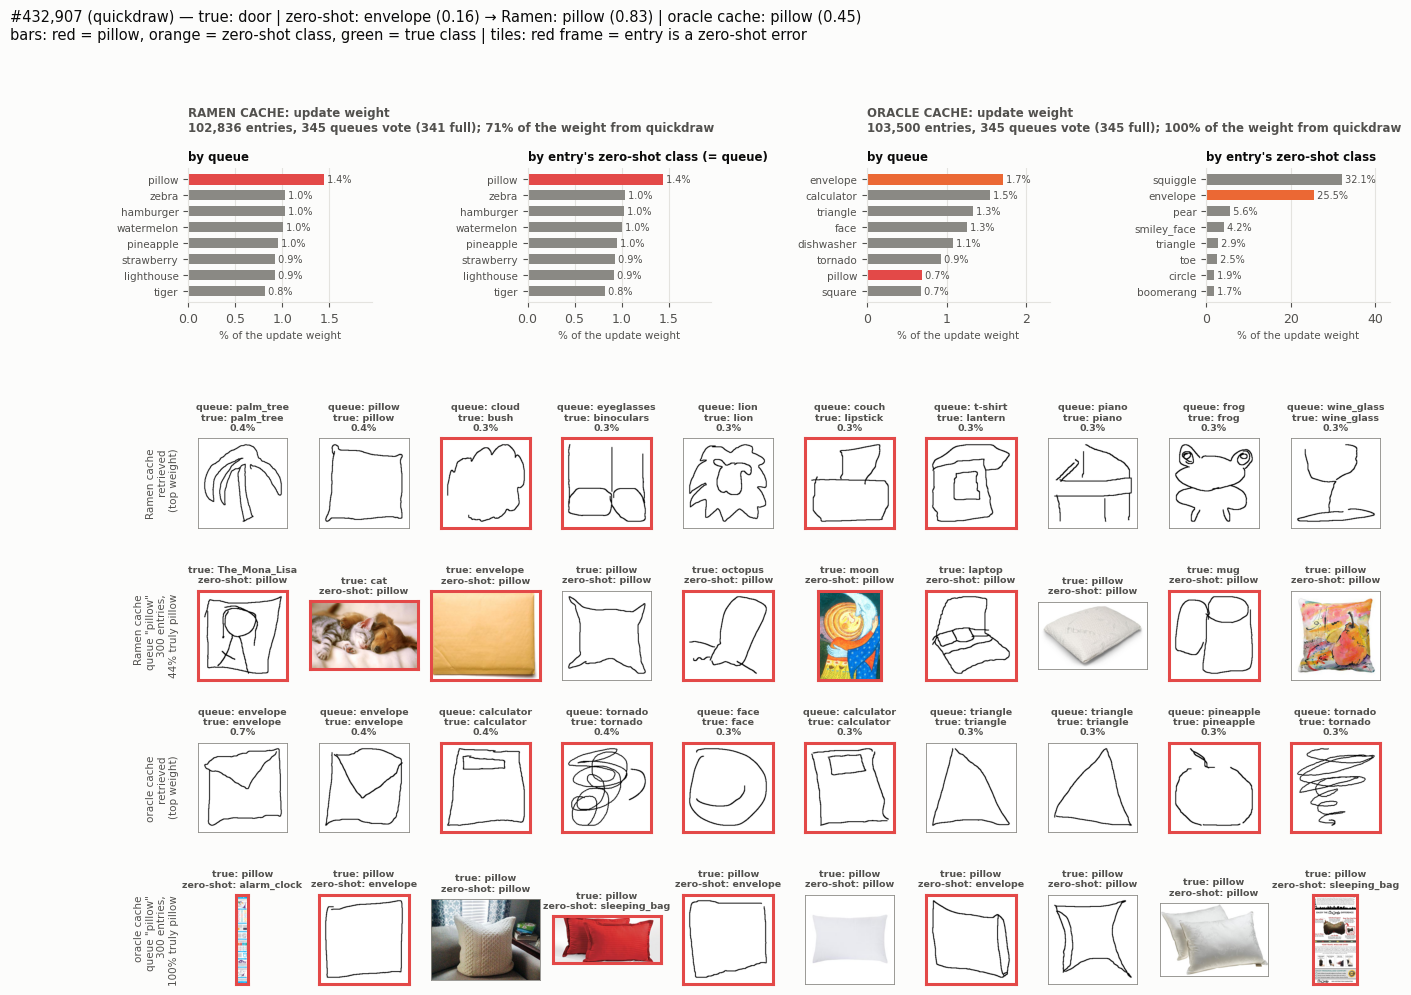

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,1.4,0.7
from zero-shot-class queue,0.6,1.7
from true-class queue,0.2,0.4
entries truly pillow,1.4,0.7
entries zero-shot-predicted pillow,1.4,1.1
entries zero-shot-predicted as query's zero-shot class,0.6,25.5
entries truly query's class,0.2,0.4
entries that are zero-shot errors,49.1,91.1
entries from query's domain,71.0,100.0


In [14]:
study.show_example(0)

### Example 2: zero-shot *envelope* → Ramen wrong pillow, oracle cache: still pillow
Image #534,661 of the stream (89.7% in), domain **quickdraw**, true class **laptop**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
laptop,true,25.18,24.40,21.01,0.002,0.000,0.000
envelope,zero-shot,30.11,27.06,29.35,0.259,0.004,0.162
pillow,"Ramen, oracle, target",28.26,32.38,30.88,0.041,0.847,0.759
couch,,26.47,29.61,25.86,0.007,0.053,0.005
sock,,28.42,26.73,25.92,0.048,0.003,0.005
foot,,28.26,26.08,24.96,0.041,0.002,0.002
sleeping_bag,,26.48,29.22,27.40,0.007,0.036,0.023
toe,,28.10,25.55,24.79,0.035,0.001,0.002


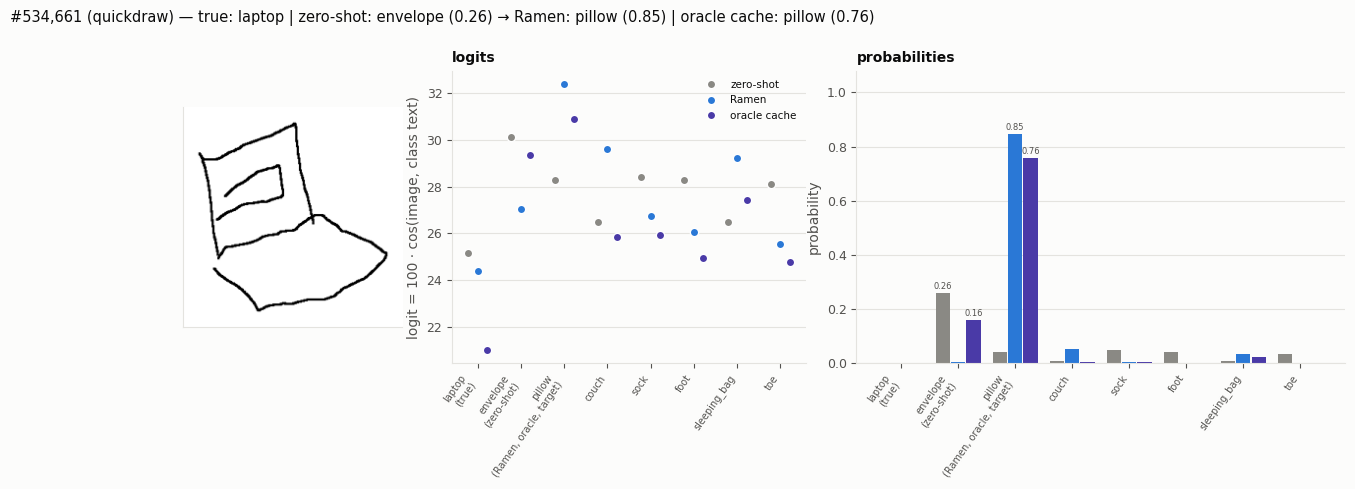

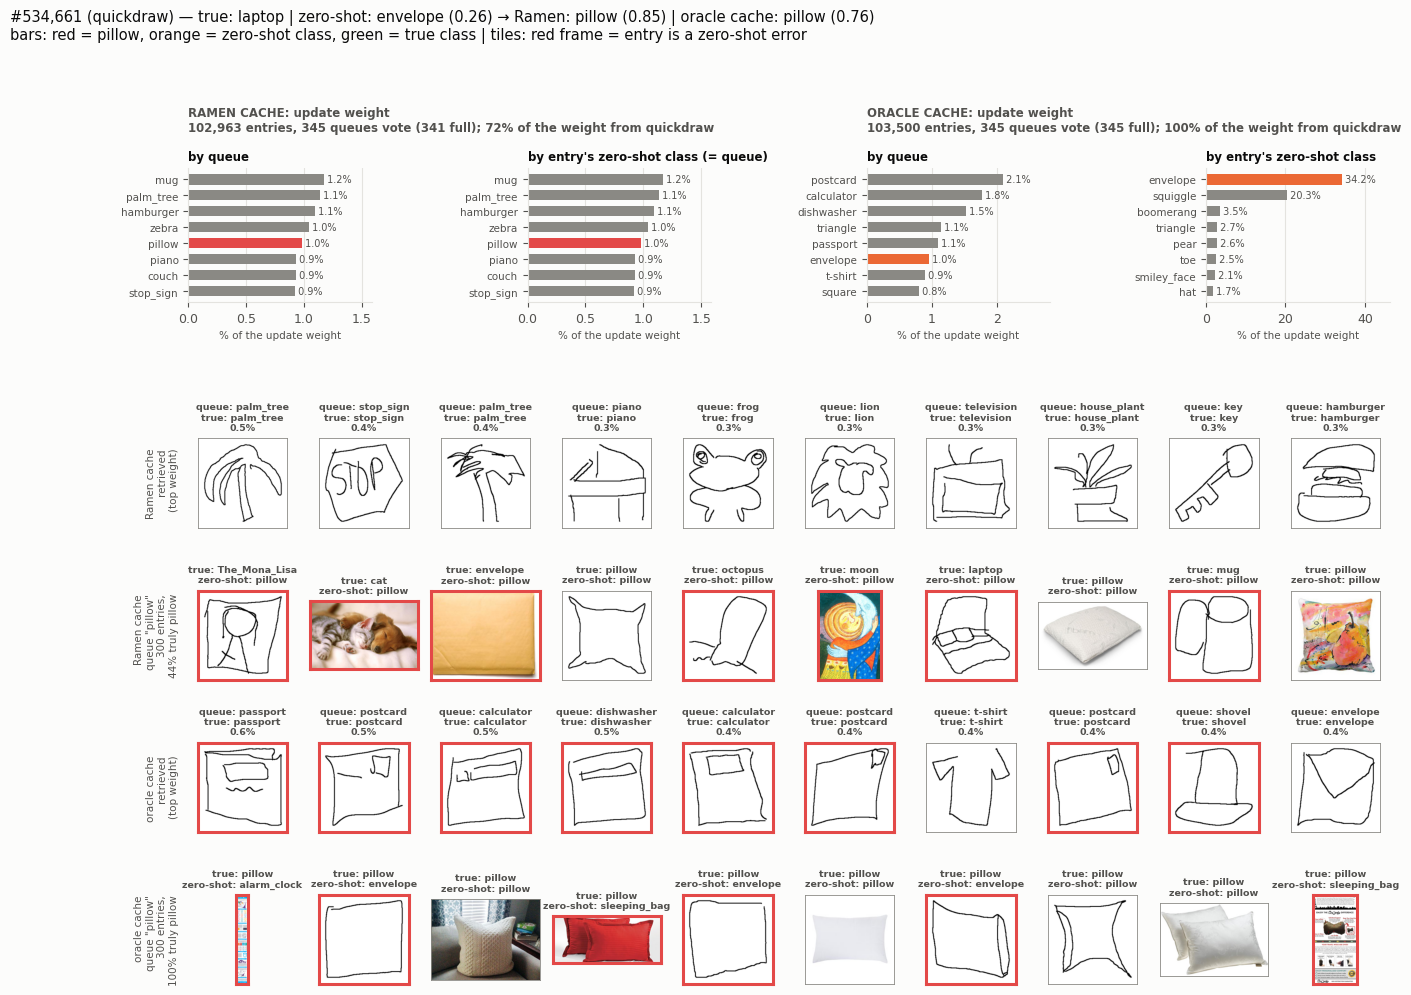

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,1.0,0.7
from zero-shot-class queue,0.6,1.0
from true-class queue,0.5,0.7
entries truly pillow,0.2,0.7
entries zero-shot-predicted pillow,1.0,1.3
entries zero-shot-predicted as query's zero-shot class,0.6,34.2
entries truly query's class,1.5,0.7
entries that are zero-shot errors,49.9,91.1
entries from query's domain,72.0,100.0


In [15]:
study.show_example(1)

### Example 3: zero-shot *envelope* → Ramen wrong pillow, oracle cache: other wrong
Image #336,466 of the stream (56.5% in), domain **quickdraw**, true class **book**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
book,true,25.66,27.39,23.65,0.003,0.045,0.000
envelope,"zero-shot, oracle",30.49,29.08,31.37,0.395,0.241,0.880
pillow,"Ramen, target",26.81,29.36,27.20,0.010,0.319,0.014
squiggle,,28.70,27.00,27.85,0.066,0.030,0.026
underwear,,26.54,27.17,26.27,0.008,0.035,0.005
zigzag,,27.91,26.49,26.55,0.030,0.018,0.007
map,,27.71,25.88,24.95,0.024,0.010,0.001
triangle,,27.64,25.81,26.57,0.023,0.009,0.007


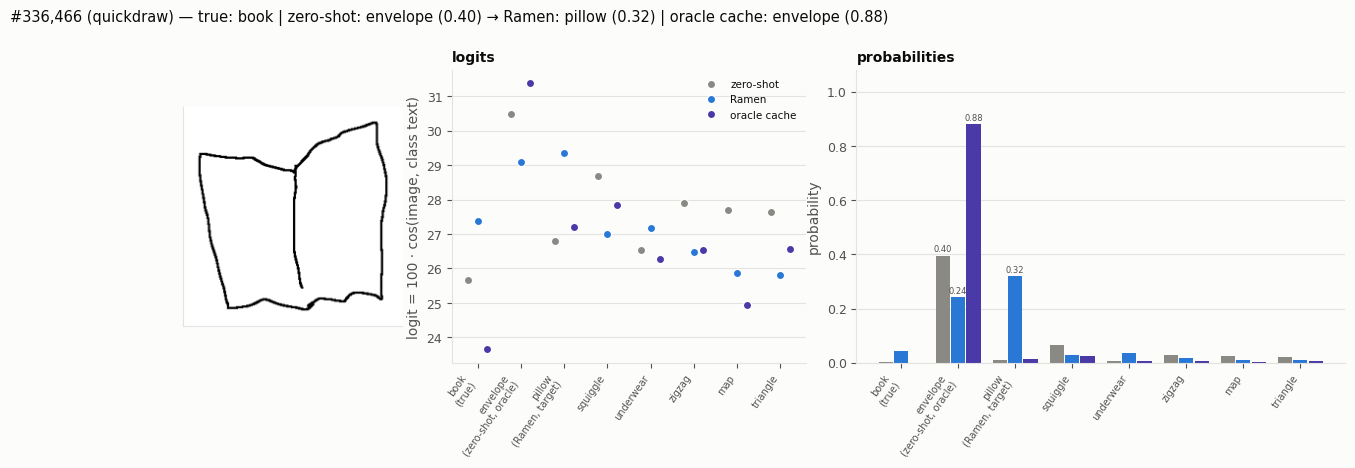

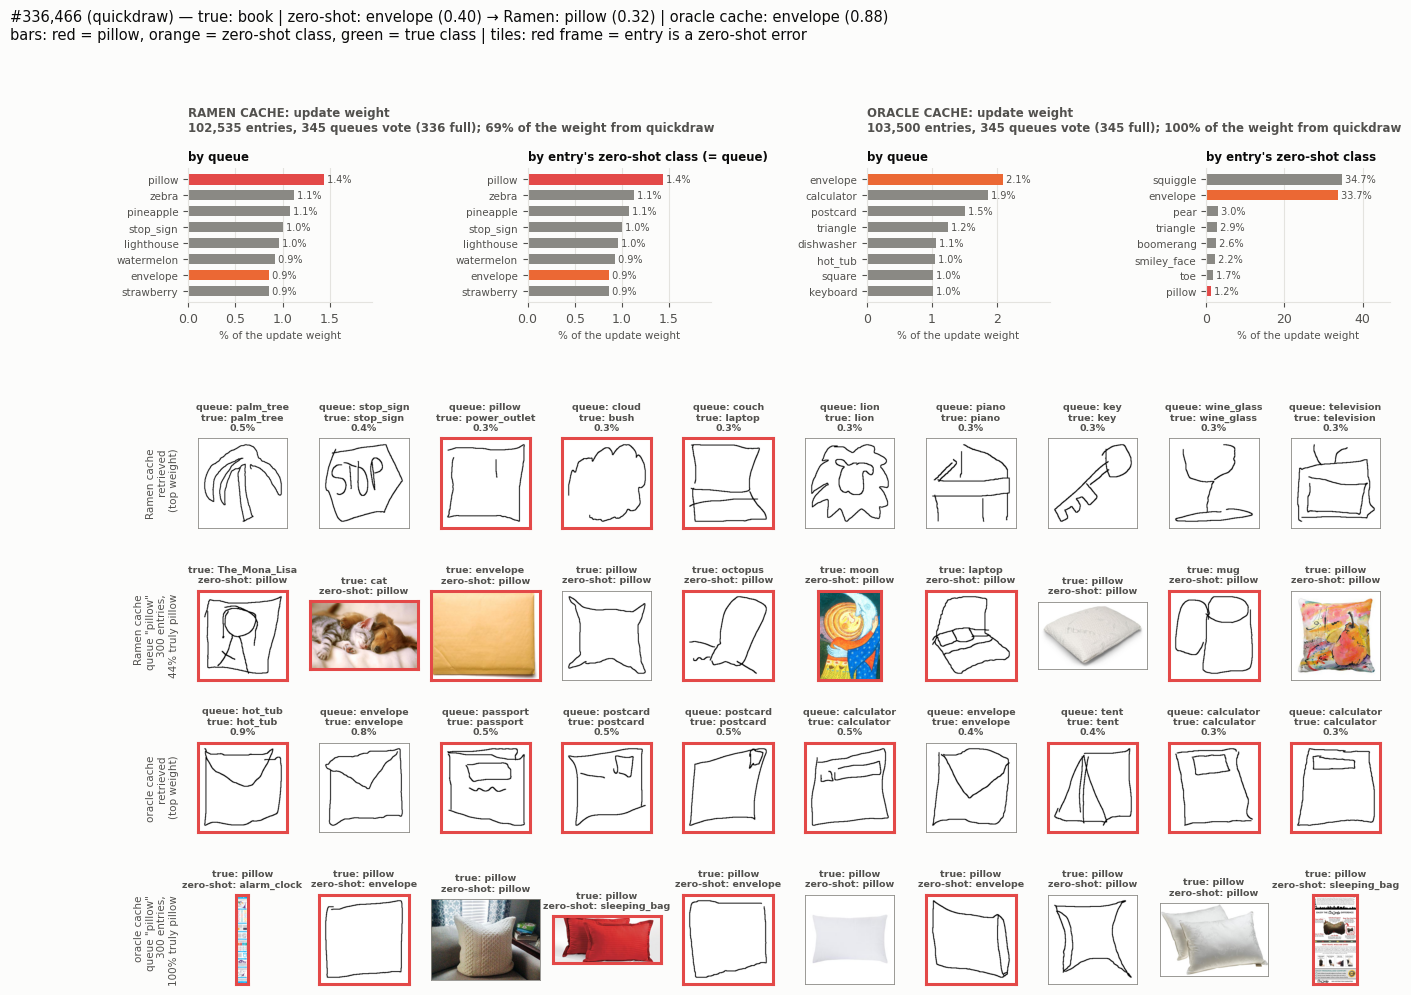

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,1.4,0.7
from zero-shot-class queue,0.9,2.1
from true-class queue,0.2,0.5
entries truly pillow,0.6,0.7
entries zero-shot-predicted pillow,1.4,1.2
entries zero-shot-predicted as query's zero-shot class,0.9,33.7
entries truly query's class,0.4,0.5
entries that are zero-shot errors,47.7,91.7
entries from query's domain,69.2,100.0


In [16]:
study.show_example(2)

### Example 4: zero-shot *squiggle* → Ramen wrong pillow, oracle cache: still pillow
Image #542,621 of the stream (91.0% in), domain **quickdraw**, true class **chair**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
chair,true,26.87,25.64,25.93,0.010,0.000,0.003
squiggle,zero-shot,29.57,26.74,30.15,0.150,0.001,0.234
pillow,"Ramen, oracle, target",28.07,34.05,30.72,0.033,0.977,0.417
envelope,,29.01,26.14,28.76,0.085,0.000,0.059
zigzag,,28.13,25.00,27.96,0.036,0.000,0.026
pants,,27.96,25.84,26.52,0.030,0.000,0.006
stitches,,27.04,24.72,28.04,0.012,0.000,0.029
couch,,26.12,29.62,27.76,0.005,0.012,0.022


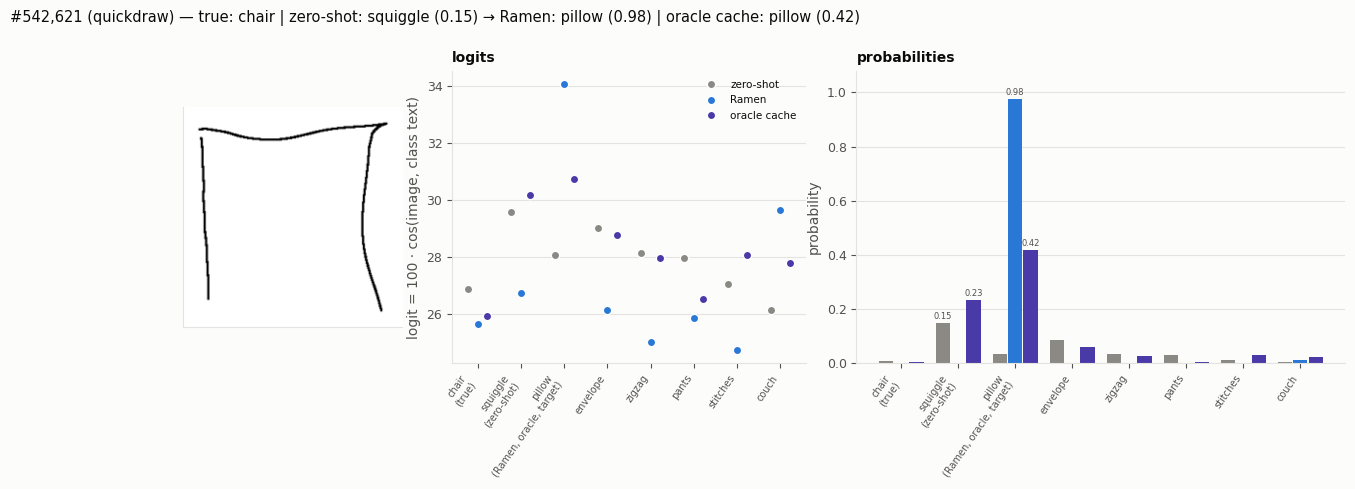

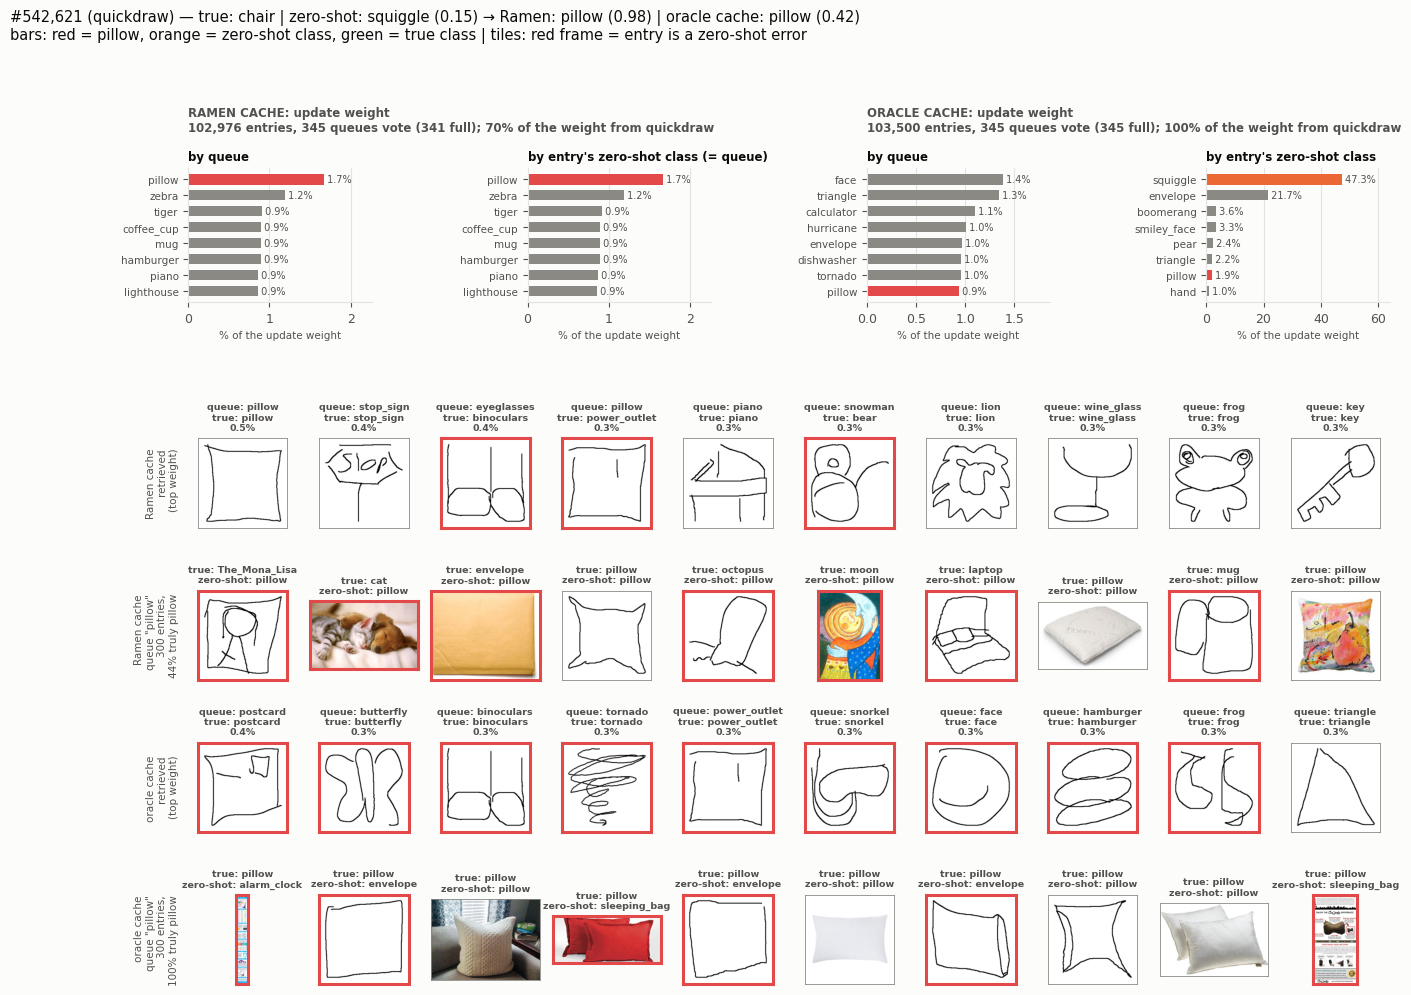

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,1.7,0.9
from zero-shot-class queue,0.3,0.6
from true-class queue,0.3,0.2
entries truly pillow,1.2,0.9
entries zero-shot-predicted pillow,1.7,1.9
entries zero-shot-predicted as query's zero-shot class,0.3,47.3
entries truly query's class,0.5,0.2
entries that are zero-shot errors,49.6,92.9
entries from query's domain,70.4,100.0


In [17]:
study.show_example(3)

### Example 5: zero-shot *squiggle* → Ramen wrong pillow, oracle cache: other wrong
Image #509,175 of the stream (85.4% in), domain **quickdraw**, true class **map**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
map,true,26.88,27.23,25.47,0.020,0.029,0.002
squiggle,"zero-shot, oracle",29.18,28.58,30.70,0.205,0.112,0.364
pillow,"Ramen, target",26.77,28.79,27.44,0.018,0.137,0.014
envelope,,28.51,28.69,30.39,0.103,0.125,0.266
smiley_face,,27.61,27.08,29.89,0.042,0.025,0.161
square,,27.39,26.92,26.36,0.034,0.021,0.005
toe,,26.75,26.27,26.88,0.018,0.011,0.008
sleeping_bag,,24.54,26.73,24.89,0.002,0.017,0.001


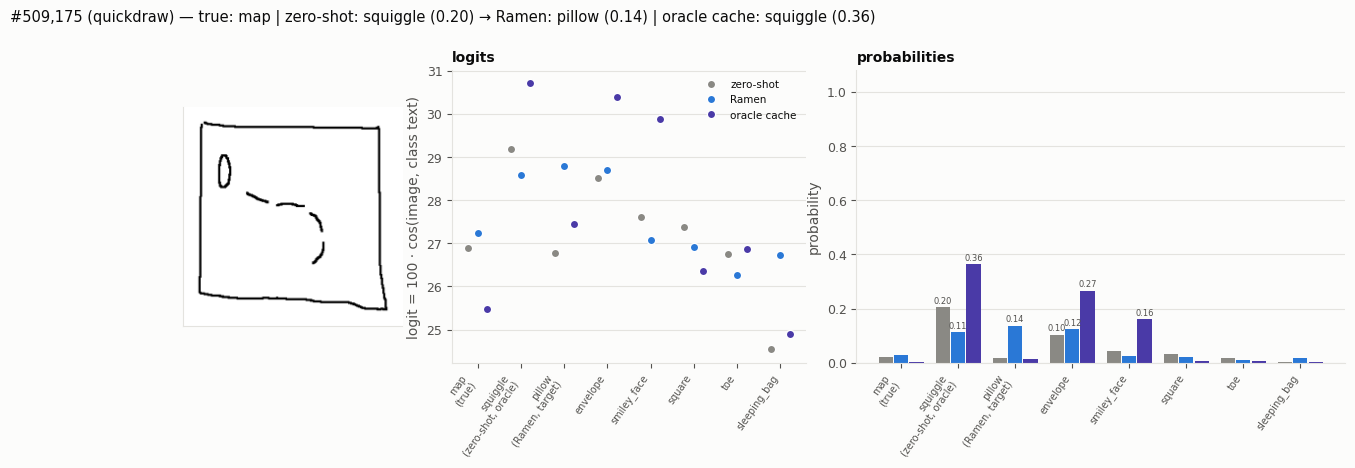

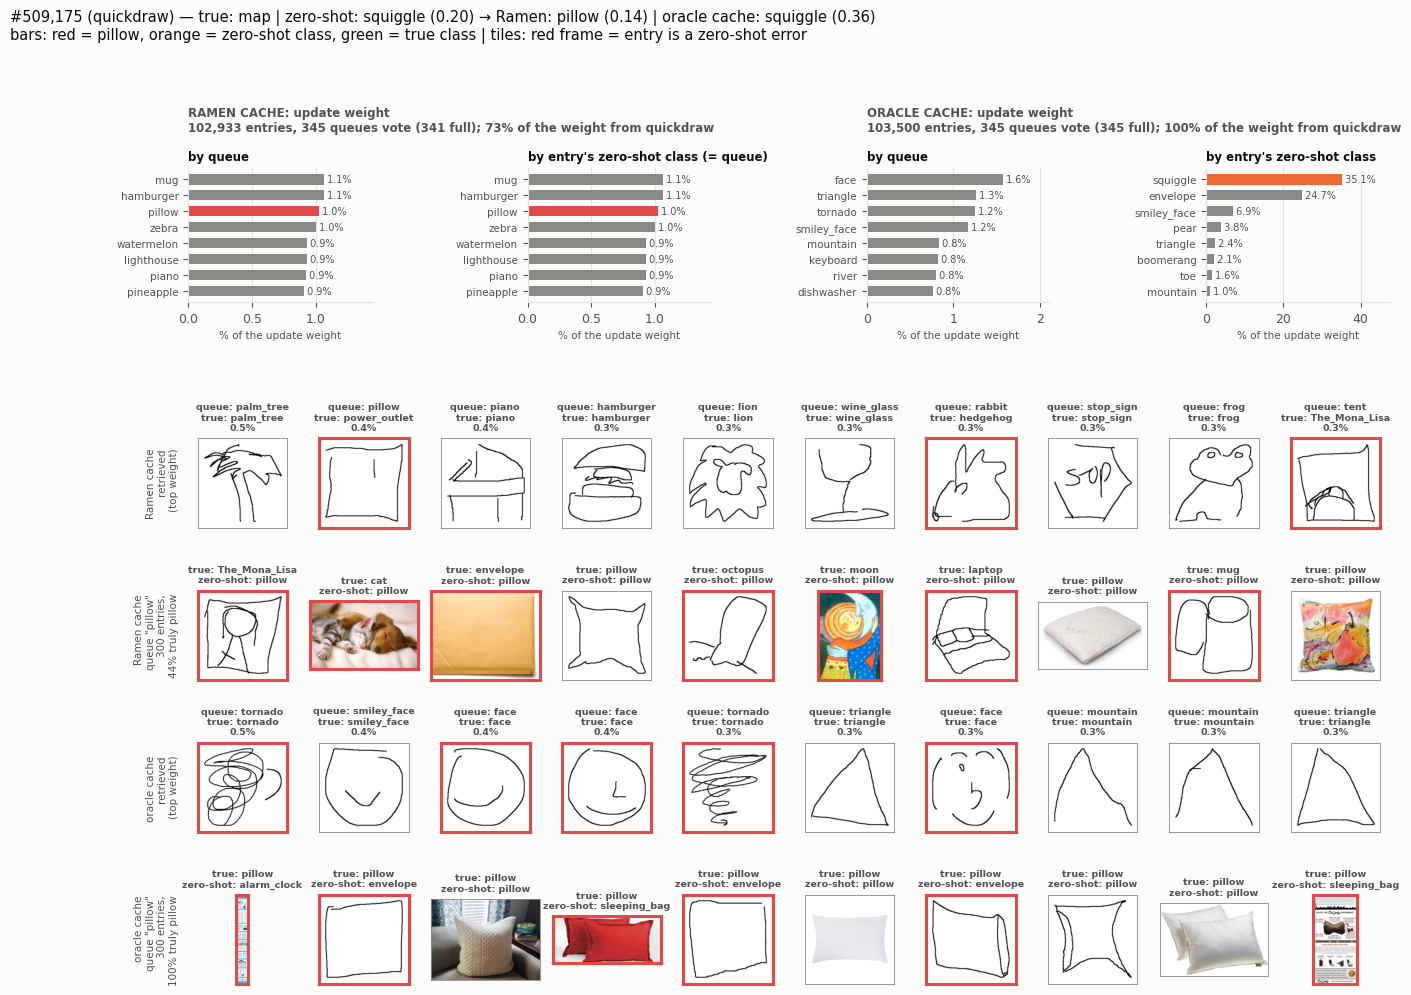

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,1.0,0.6
from zero-shot-class queue,0.4,0.4
from true-class queue,0.2,0.5
entries truly pillow,0.3,0.6
entries zero-shot-predicted pillow,1.0,0.9
entries zero-shot-predicted as query's zero-shot class,0.4,35.1
entries truly query's class,0.1,0.5
entries that are zero-shot errors,51.1,90.5
entries from query's domain,72.7,100.0


In [18]:
study.show_example(4)

### Example 6: zero-shot *pillow* → Ramen wrong pillow
Image #471,070 of the stream (79.0% in), domain **painting**, true class **squiggle**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
squiggle,true,22.72,21.28,21.31,0.010,0.006,0.006
pillow,"zero-shot, Ramen, oracle, target",26.61,25.55,25.70,0.467,0.445,0.513
sleeping_bag,,24.81,23.87,23.89,0.077,0.084,0.084
lollipop,,24.29,23.33,22.84,0.046,0.048,0.029
bed,,23.70,22.98,23.18,0.026,0.034,0.041
peas,,23.89,23.12,23.12,0.031,0.039,0.039
camouflage,,23.89,22.89,22.91,0.031,0.031,0.032
parachute,,23.91,22.91,22.59,0.031,0.032,0.023


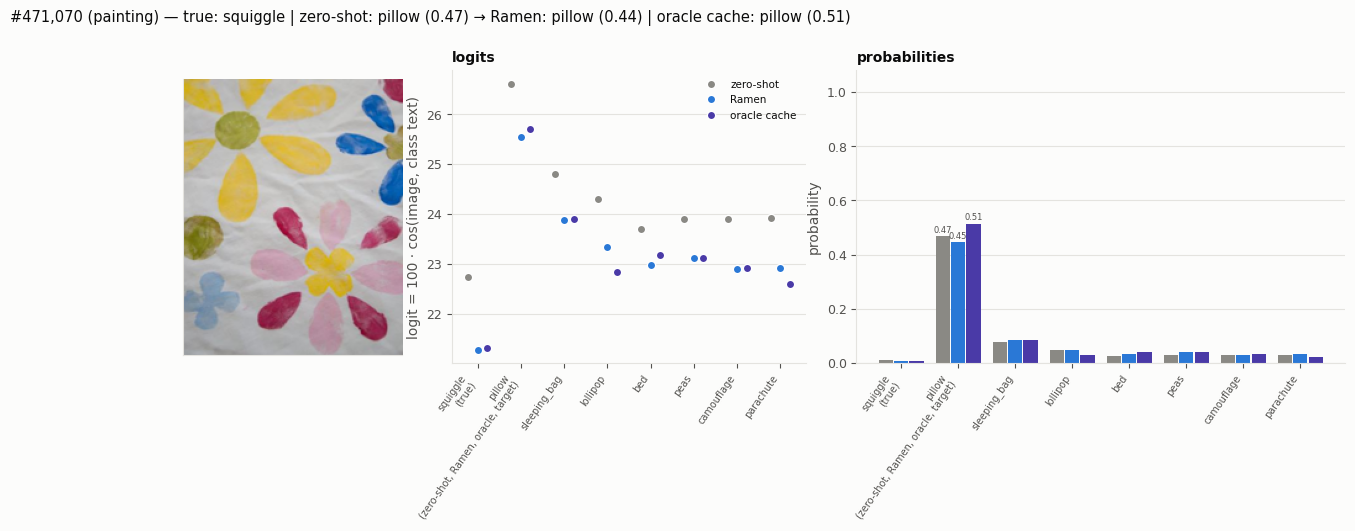

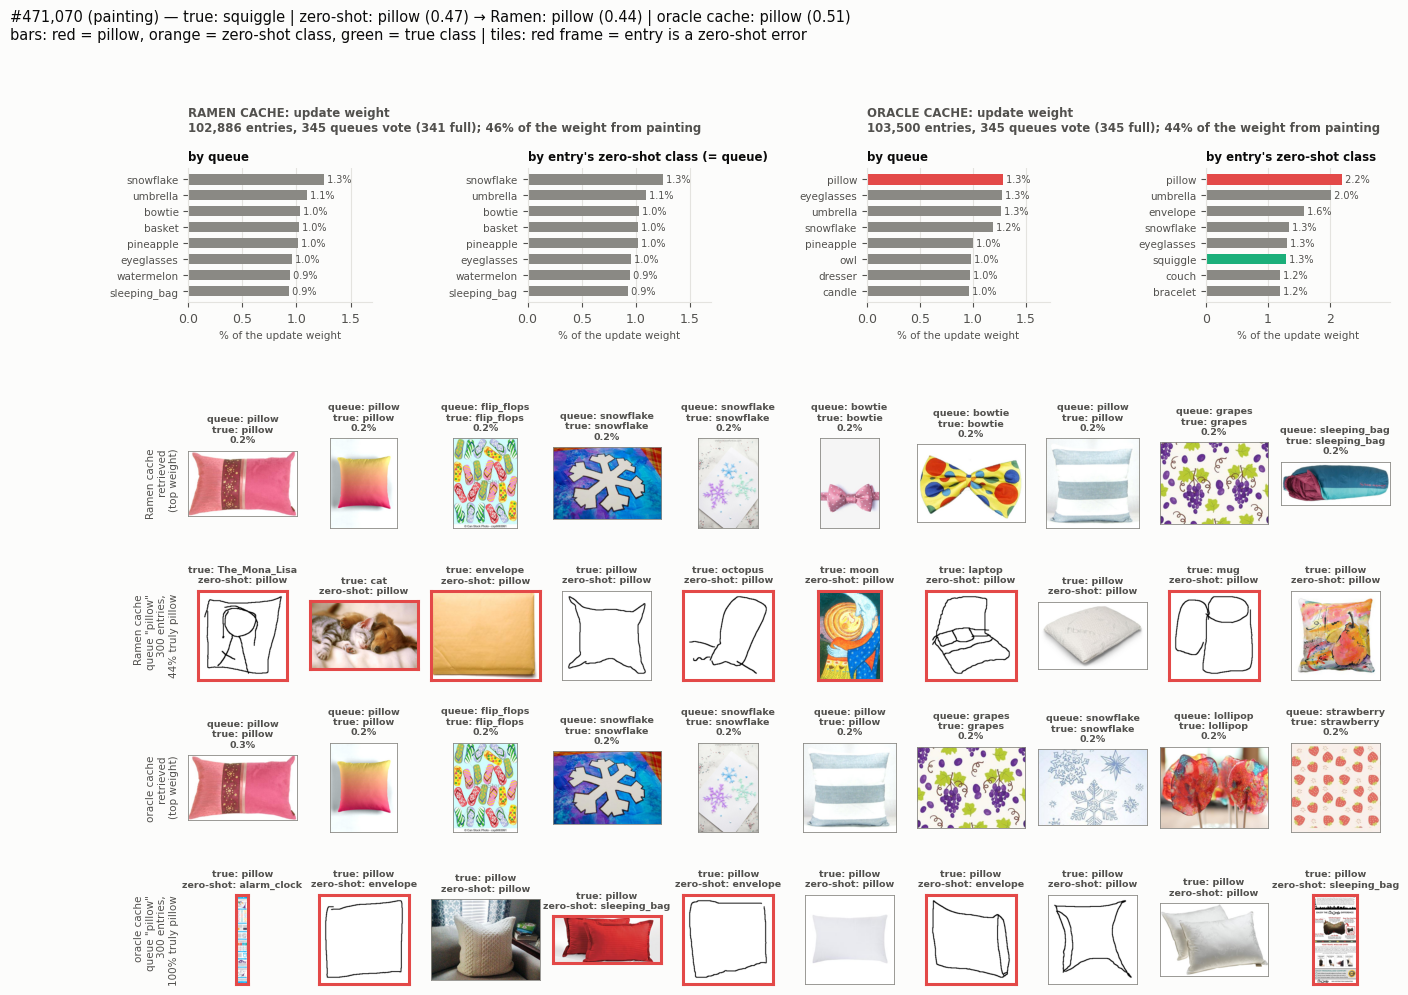

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,0.8,1.3
from zero-shot-class queue,0.8,1.3
from true-class queue,0.1,0.1
entries truly pillow,0.8,1.3
entries zero-shot-predicted pillow,0.8,2.2
entries zero-shot-predicted as query's zero-shot class,0.8,2.2
entries truly query's class,0.2,0.1
entries that are zero-shot errors,17.1,22.9
entries from query's domain,46.4,43.9


In [19]:
study.show_example(5)

### Example 7: zero-shot *envelope* → Ramen correct
Image #447,664 of the stream (75.1% in), domain **clipart**, true class **book**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
book,"true, Ramen",24.43,24.06,23.94,0.130,0.185,0.172
envelope,"zero-shot, oracle",24.54,23.96,24.26,0.145,0.168,0.238
pillow,target,19.53,18.60,18.26,0.001,0.001,0.001
spreadsheet,,24.02,23.56,23.62,0.085,0.112,0.126
calendar,,23.93,23.41,22.95,0.079,0.097,0.064
postcard,,23.38,22.86,22.71,0.045,0.056,0.050
brain,,23.29,22.27,21.86,0.041,0.031,0.021
paper_clip,,23.18,22.39,22.34,0.037,0.035,0.035


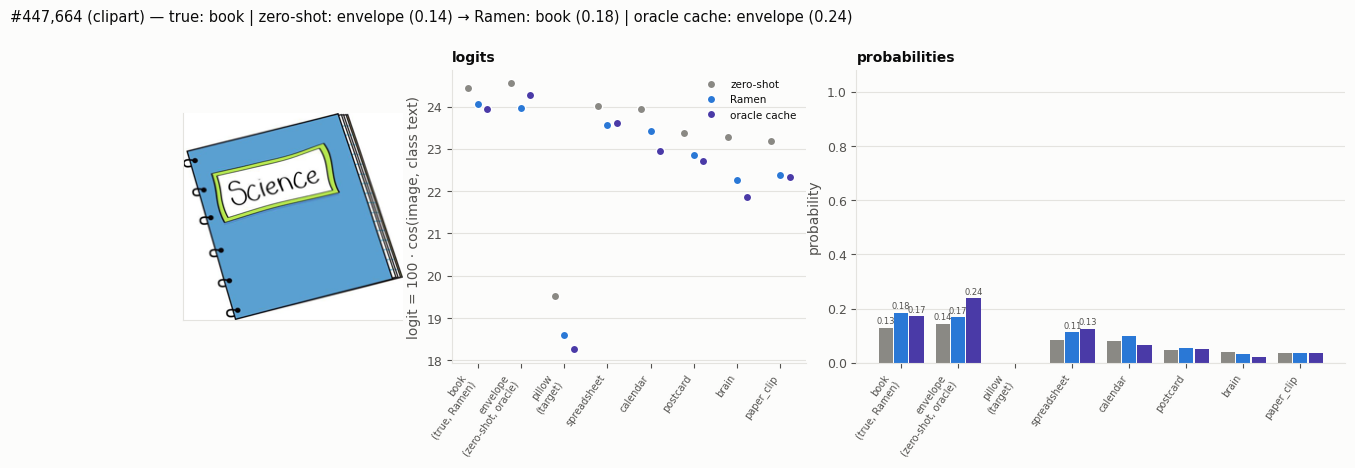

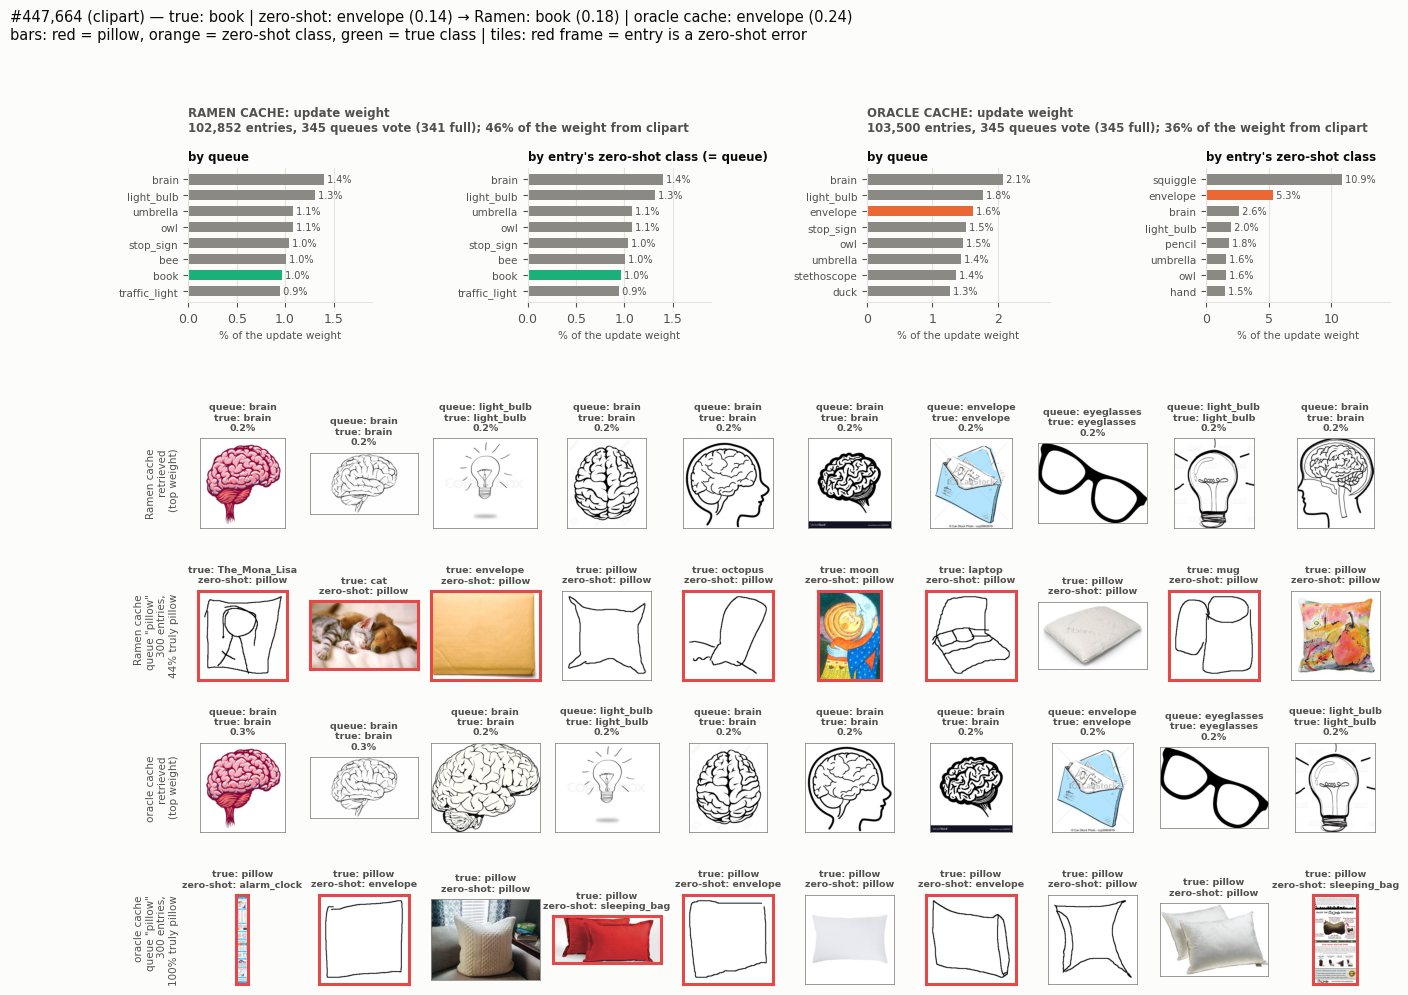

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,0.2,0.2
from zero-shot-class queue,0.3,1.6
from true-class queue,1.0,1.2
entries truly pillow,0.1,0.2
entries zero-shot-predicted pillow,0.2,0.1
entries zero-shot-predicted as query's zero-shot class,0.3,5.3
entries truly query's class,1.2,1.2
entries that are zero-shot errors,15.8,34.0
entries from query's domain,46.2,35.9


In [20]:
study.show_example(6)

### Example 8: zero-shot *pillow* → Ramen right pillow
Image #328,061 of the stream (55.0% in), domain **real**, true class **pillow**.

,roles,logit zero-shot,logit Ramen,logit oracle cache,prob zero-shot,prob Ramen,prob oracle cache
pillow,"true, zero-shot, Ramen, oracle, target",32.55,34.43,34.34,0.987,0.998,0.998
bed,,27.93,27.96,28.13,0.010,0.002,0.002
alarm_clock,,24.91,24.04,24.49,0.000,0.000,0.000
couch,,24.72,25.36,25.09,0.000,0.000,0.000
elbow,,23.65,23.37,23.40,0.000,0.000,0.000
sleeping_bag,,23.65,23.95,23.99,0.000,0.000,0.000
arm,,23.51,23.00,23.11,0.000,0.000,0.000
underwear,,22.99,22.80,22.62,0.000,0.000,0.000


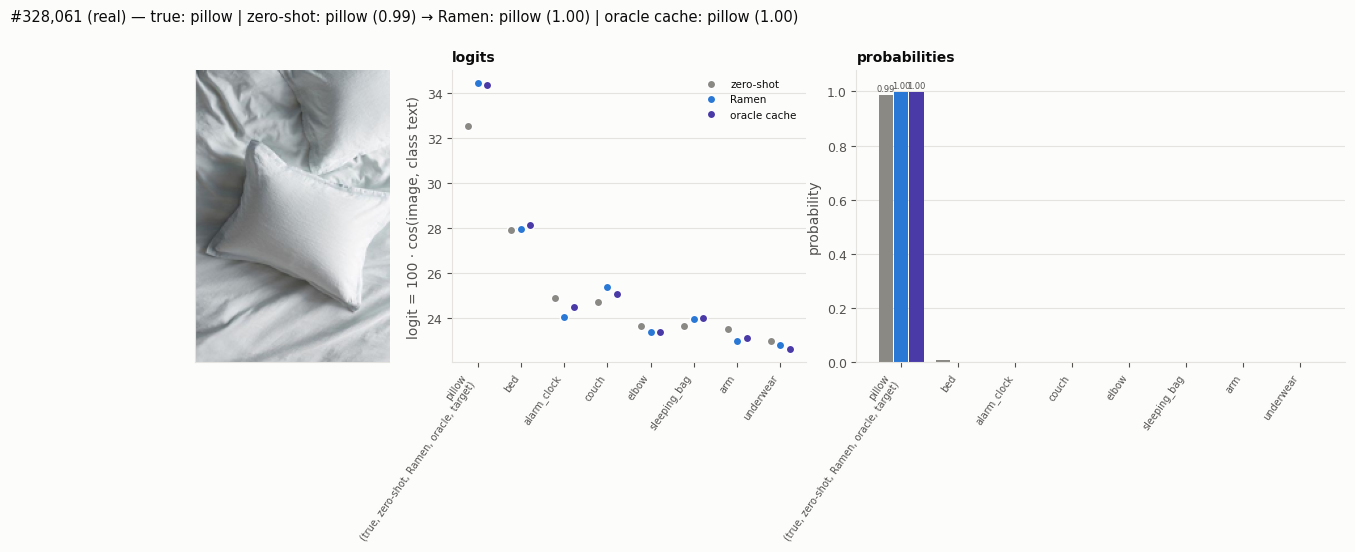

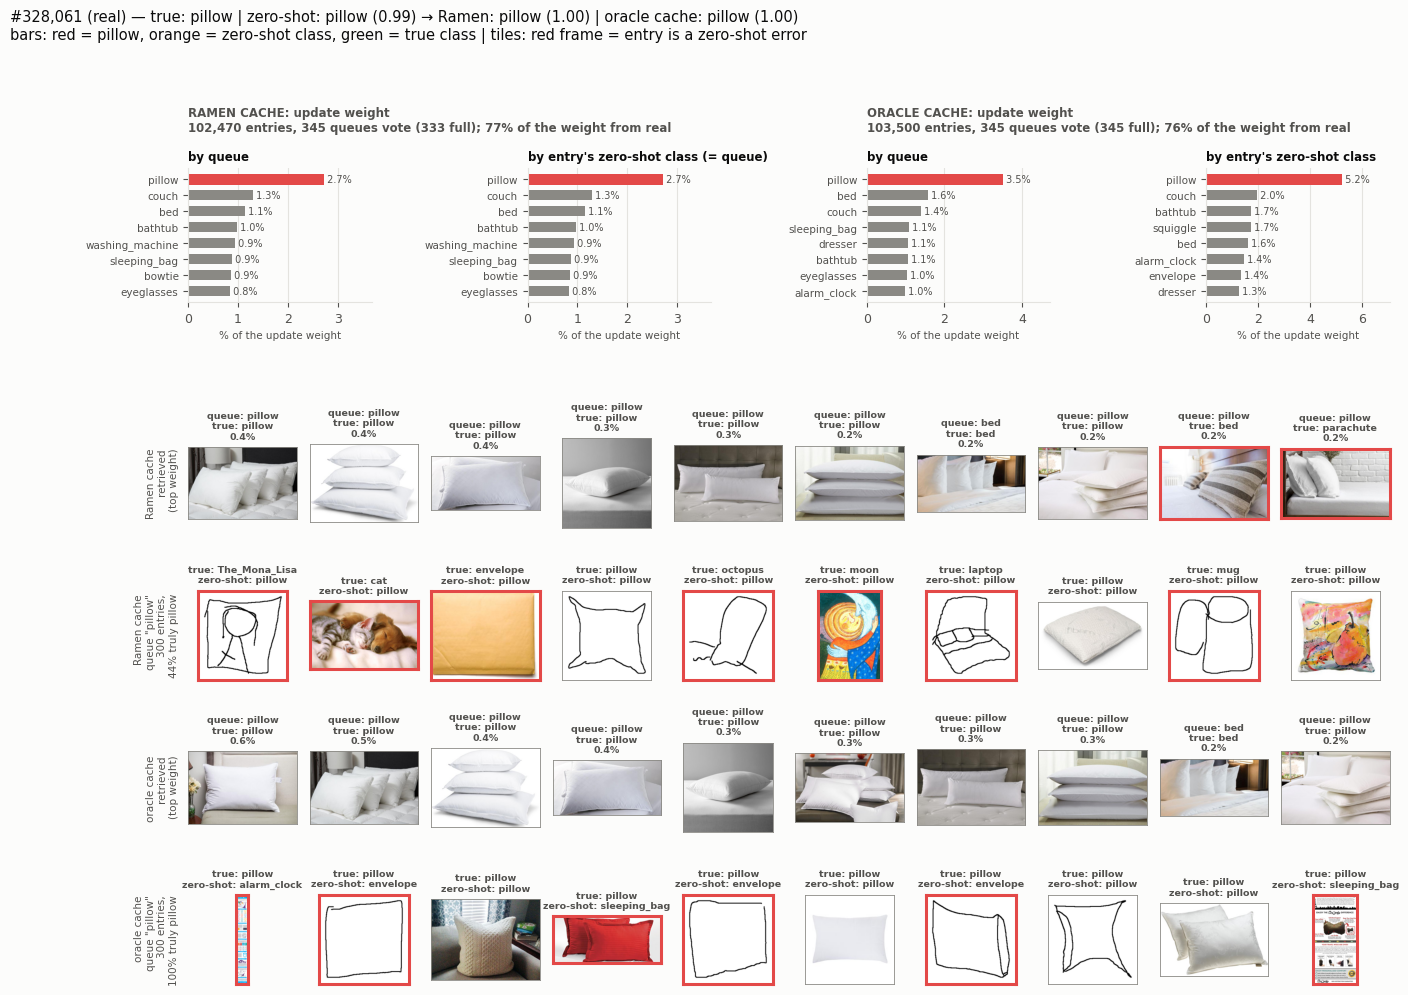

cache,Ramen cache,oracle cache
self,0.0,0.0
from pillow queue,2.7,3.5
from zero-shot-class queue,2.7,3.5
from true-class queue,2.7,3.5
entries truly pillow,2.5,3.5
entries zero-shot-predicted pillow,2.7,5.2
entries zero-shot-predicted as query's zero-shot class,2.7,5.2
entries truly query's class,2.5,3.5
entries that are zero-shot errors,10.8,17.4
entries from query's domain,76.7,75.8


In [21]:
study.show_example(7)

## 7. Interpretation

**What the numbers show (seed 0, 596,006 images).**
- **The sink.** Zero-shot predicts *pillow* 2,101 times (1,147 wrong); Ramen predicts it 7,605 times (6,484
  wrong). 1,736 images are truly *pillow*. 6,129 of the 6,484 wrong ones (94.5%) are quickdraw sketches of
  rectangular objects (square, laptop, picture_frame, door, map, ...). Their zero-shot class was mostly *envelope*
  (3,570, 55.1%) or *squiggle* (1,248, 19.2%). The sink appears on every seed: 6,142–6,484 wrong *pillow*
  predictions over seeds 0–4.
- **H1 (contamination) is rejected.** With every queue filed by true label, 2,166 of the 6,484 (33.4%) stay at
  *pillow*, above the 20% the hypothesis allowed, and only 42 (0.6%) become correct. The oracle does remove
  two-thirds of the sink, but 3,499 of the 4,318 images it moves (81%) go **back to their zero-shot class**
  (mostly *envelope* and *squiggle*). On quickdraw the oracle keeps the zero-shot prediction for 66.8% of images,
  Ramen for 48.0%. Its quickdraw accuracy (11.05%) is below zero-shot's (13.33%) and Ramen's (17.54%). A pure
  cache makes Ramen adapt less on quickdraw; it does not fix the rectangles.
- **H2 as written is also rejected.** The two caches do *not* retrieve the same entries: for the wrong *pillow*s
  only 12–23% of the update weight falls on entries both retrieve.
- **What the caches do show.** Every image's update is a vote of all 345 queues with about 1% each. The *pillow*
  queue gives only about 1%, and entries that are truly *pillow* about 1%. So the sink does not come from
  retrieving *pillow* entries. What differs is where the entries come from:
  - **Oracle cache:** 90–99% of the weight comes from the image's own domain, and 78–89% sits on entries that are
    zero-shot errors. Each class queue now holds that class's own quickdraw sketches, and for a rectangle query
    the nearest ones are rectangle sketches (postcard, passport, calculator) that zero-shot calls *envelope* or
    *squiggle*. Their stored gradients sharpen *those* predictions, which fits the images returning to *envelope*
    and *squiggle*.
  - **Ramen cache:** 62–67% of the weight comes from quickdraw and 42–47% from zero-shot errors. The top-weighted
    entries are confident, correctly classified sketches of unrelated classes (palm tree, stop sign, frog),
    because quickdraw rectangles have been filed away under *envelope*, *squiggle* and *pillow*.
- **Controls.** For true *pillow* images that both models get right (mostly real photos), the two caches look alike:
  about 56–61% shared weight and 57–60% from the image's own domain. Filing only matters where zero-shot is badly
  wrong, i.e. quickdraw. For zero-shot *envelope* errors that Ramen fixes (800), the Ramen-cache statistics look
  like those of the images it sends to *pillow* (60% same domain, 42% zero-shot errors). These retrieval
  statistics do not separate a repair from a sink, as earlier replays also found.
- **The *pillow* queue itself.** In Ramen's cache it is 44% truly *pillow* and 41% quickdraw, and it stops changing
  after image 147,057 (24.7% of the stream; fp16 counter). So the late examples see a cache built from the first
  quarter of the stream.

**What this does not show.** The replay knows which entries are retrieved and with what weight, but not their
gradients. So it cannot say *which* entries turn the summed step toward *pillow*. The leading candidate is the
mix of confident non-rectangle quickdraw entries and other-domain entries, which pure queues remove. That is a
hypothesis, not a result. The mechanism numbers are from seed 0 only.

**Next step.** Step 5 of the plan (GPU, about 200 images): recompute the retrieved entries' gradients for wrong
*pillow* images and remove one group at a time from Ramen's retrieval: other-domain entries, confident correct
entries, the *envelope* / *squiggle* / *pillow* queues. The prediction is that removing other-domain entries
sends them back to *envelope* / *squiggle* as the oracle does. If none of these groups changes the prediction, the
step direction is a property of the whole 345-queue average, and a fix has to act on the update (e.g. its size
per domain) rather than on what is retrieved.

## 8. Glossary

| term | meaning |
|---|---|
| zero-shot | CLIP classifies by cosine similarity between the image embedding and each class's text embedding (7 prompt templates averaged). No adaptation. |
| Ramen | test-time adaptation. Each image is written into a class queue with its own entropy gradient. The gradients of the nearest stored entries are retrieved, one signSGD step is taken on the image encoder's LayerNorm parameters, the image is predicted, and the parameters are reset. |
| cache / queue | Ramen's memory: one queue of up to 300 entries per class. An entry is (zero-shot feature, own gradient, zero-shot entropy, arrival counter). |
| filing | which queue an image is written to. Ramen uses its zero-shot prediction; the oracle uses its true label. |
| oracle cache | the Ramen run whose cache is filed by true label (`RamenTrueLabel`). It uses ground truth, so it is an upper bound on what a perfectly filed cache could do, not a method. |
| retrieved entries / update weight | for each test image, the top 10 nearest entries of every non-empty queue, weighted e^(−H)·e^(−β·d). Queues are averaged. "Share of the update" = an entry's weight / total weight. |
| self | the test image's own entry: it is written before retrieval, at distance 0. |
| sink | a class that a model predicts for many images of other classes. |
| route | the zero-shot class an image had before Ramen moved it to the sink. |
| fp16 priority freeze | Ramen counts arrivals in fp16, which becomes inf after 65,520 images. After that, new entries (priority inf) replace a full queue's older finite-priority entries once, and then the queue stops changing (the *pillow* queue last changes at image 147,057). |
| zero-shot error (entry) | a cache entry whose zero-shot prediction is not its true class; its stored gradient sharpens that wrong class. |
| logit | 100 · cos(image embedding, class text embedding). The probability is the softmax over the 345 logits. |
| domain average | the mean of the 6 per-domain accuracies (the headline convention). |
